# Xenium mouse kidney: a 3D segmentation-free cell-type map

This tutorial runs the SSAF-T pipeline in **3D** on one Xenium section of a healthy mouse kidney:

1. load the Xenium output into SpatialData and add the 11-plane morphology z-stack as an image element
2. tile the section for chunked processing
3. downsample in 3D: sample anchor positions on every morphology plane and compute a 3D KDE vector at each
4. cluster the anchors
5. annotate the clusters with CeLLMan (`annotate-mode`, run outside the notebook)
6. map cell types over the whole 3D vector field
7. filter the map
8. cut the map into single cells with the Xenium nuclei

> Dataset: Xuanyuan, Q., Wu, H., Sundaramoorthi, H. et al. *Multimodal spatial transcriptomic characterization of
> mouse kidney injury and repair.* Nat Commun 16, 7567 (2025). https://doi.org/10.1038/s41467-025-62599-9

## Data

The section is the sham-operated right kidney (`ShamR`, male) of GEO series
[GSE269719](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE269719), sample
[GSM8325616](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM8325616). Download the Xenium output bundle
next to this notebook:

```bash
mkdir -p data/xenium_kidney && cd data/xenium_kidney
wget -O GSM8325616_xenium_shamR_male_output.tar.gz \
  "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSM8325616&format=file&file=GSM8325616_xenium_shamR_male_output.tar.gz"
tar xzf GSM8325616_xenium_shamR_male_output.tar.gz
```

This gives `data/xenium_kidney/ShamR-output-XETG00063__0005295__Region_6__20230717__191520/`. Everything the
notebook writes goes to `outputs/xenium_kidney/` (about 60 GB, most of it the z-stack and its tiles).

A CUDA GPU is required for the KDE, the mapping and `rapids_singlecell`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ssaft

DATA  = Path("data/xenium_kidney/ShamR-output-XETG00063__0005295__Region_6__20230717__191520")
OUT   = Path("outputs/xenium_kidney")
ZARR  = OUT / "spatialdata.zarr"        # Xenium outputs + the morphology z-stack
CROPS = OUT / "spatialdata_crops"       # tiles for chunked downsampling
STORE = OUT / "ssaft_store"             # SSAF-T zarr store: anchors, vector-field norms, cell-type maps
CLS   = OUT / "mouse_kidney_cls.h5ad"   # clustered anchors, the input of annotate-mode
ANNOTATION = OUT / "annotation_out"     # written by annotate-mode

DEVICE = "cuda"
NCORES = 30
OUT.mkdir(parents=True, exist_ok=True)

## 1. Load the sample and add the morphology z-stack

`spatialdata_io.xenium` loads the transcripts (with their `z`), the nucleus boundaries and two **2D** morphology
images, `morphology_focus` and `morphology_mip`. A 2D image carries no depth, so it cannot say where along z the
tissue is. The full stack, `morphology.ome.tif`, has 11 DAPI planes 3 µm apart.

`Analysis.zstack_image` wraps that file as a 3D image element `(c, z, y, x)` without reading it into memory.
`like=` puts it on the pixel grid of `morphology_focus`, so it overlays the transcripts exactly. Plane `k` sits at
`z = k * PhysicalSizeZ` µm, in the same units as the transcripts' `z`. `downsample_vector(z=3)` reads its planes
only from `sdata.images`, so the stack has to be added there and written with the rest of the SpatialData.

In [2]:
import spatialdata as sd
import spatialdata_io

sdata = spatialdata_io.xenium(DATA)
sdata.images["morphology_zstack"] = ssaft.Analysis.zstack_image(
    DATA / "morphology.ome.tif", like=sdata.images["morphology_focus"])
sdata.write(ZARR)
sdata = sd.read_zarr(ZARR)

for kind in ("images", "labels", "points", "shapes", "tables"):
    print(f"{kind:7s}", list(getattr(sdata, kind).keys()))

images  ['morphology_focus', 'morphology_mip', 'morphology_zstack']
labels  ['cell_labels', 'nucleus_labels']
points  ['transcripts']
shapes  ['cell_boundaries', 'nucleus_boundaries']
tables  ['table']


In [3]:
from spatialdata.transformations import get_transformation

stack = sdata.images["morphology_zstack"]
print("z-stack", stack["scale0"]["image"].dims, stack["scale0"]["image"].shape)

# z of each plane in the 'global' coordinate system (SpatialData places pixel k's centre at k + 0.5)
Mz = get_transformation(stack, "global").to_affine_matrix(input_axes=("z",), output_axes=("z",))
plane_z = [float(Mz[0, 0] * (k + 0.5) + Mz[0, 1]) for k in range(stack["scale0"]["image"].sizes["z"])]
print("plane z (um):", plane_z)

tz = sdata.points["transcripts"]["z"].compute()
print("transcript z (um): 5-95% {:.1f}-{:.1f}".format(*np.percentile(tz, [5, 95])))

z-stack ('c', 'z', 'y', 'x') (1, 11, 23888, 19971)
plane z (um): [0.0, 3.0, 6.0, 9.0, 12.0, 15.0, 18.0, 21.0, 24.0, 27.0, 30.0]
transcript z (um): 5-95% 13.5-19.1


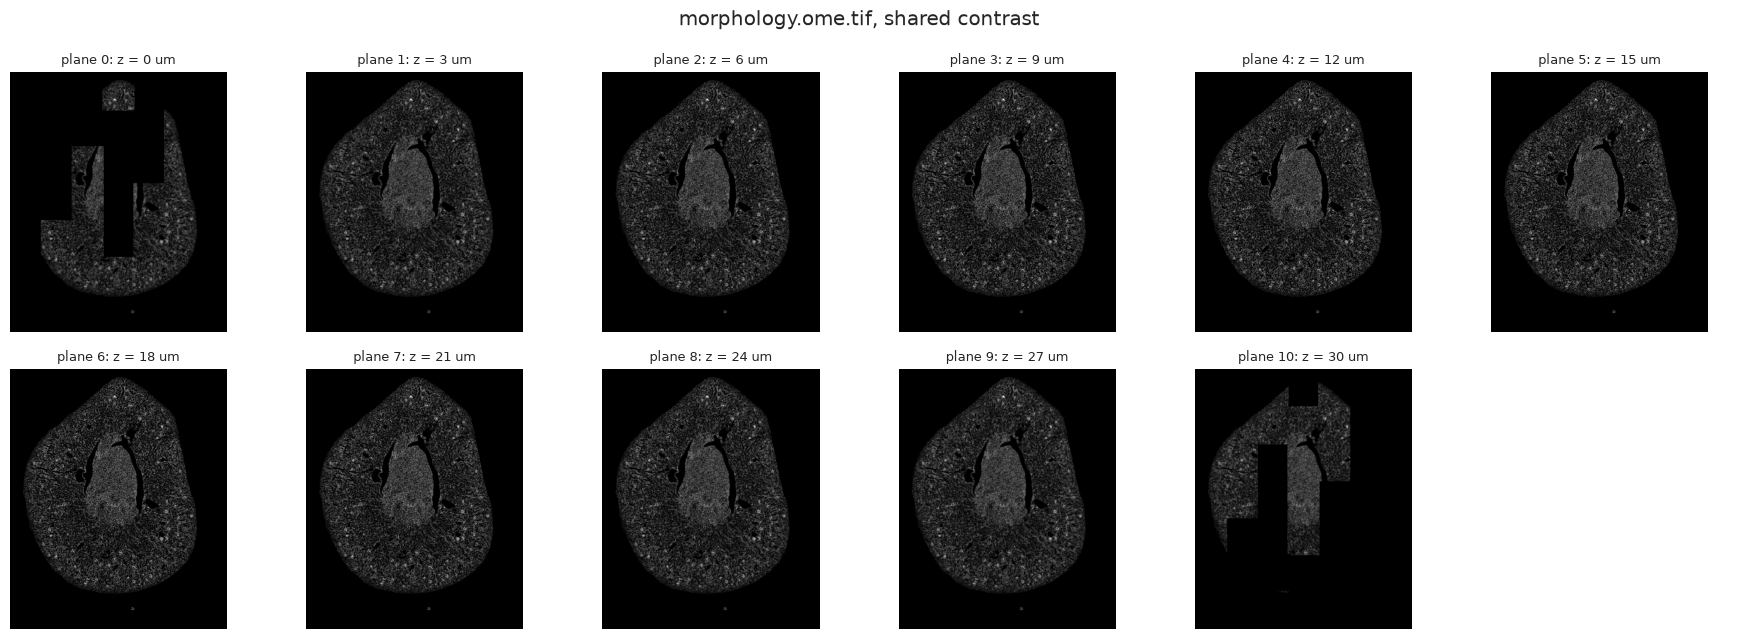

In [4]:
low = stack["scale3"]["image"].isel(c=0)          # 1/8 resolution, for display
vmax = float(np.percentile(low.isel(z=5).values, 99.5))
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for k, ax in enumerate(axes.flat):
    ax.axis("off")
    if k < low.sizes["z"]:
        ax.imshow(low.isel(z=k).values, cmap="gray", vmin=0, vmax=vmax)
        ax.set_title(f"plane {k}: z = {plane_z[k]:.0f} um", fontsize=9)
fig.suptitle("morphology.ome.tif, shared contrast")
plt.tight_layout()
plt.show()

The 6 µm FFPE section sits in the middle planes, where the transcripts are. The outer planes show the same tissue out
of focus: the microscope is widefield, so light from the section reaches every plane. The black rectangles in the
first and last planes are fields of view that were not imaged at that depth: each field of view covers 10 of the 11
planes, and the stack is zero where a field of view has no image. Any plane that falls outside
the transcripts' z range is skipped during downsampling, so no anchor is placed where there are no molecules.

## 2. Tile the section

`slice_spatialdata.py` cuts the SpatialData into square tiles (in `global` units, which are Xenium pixels here) so
`downsample_vector(chunked=True)` can stream them. `--image-key` must keep the z-stack, and the transcripts keep
their `z` column by default.

In [5]:
import subprocess, sys

SLICE = Path(ssaft.__file__).parent / "scripts" / "slice_spatialdata.py"
subprocess.run([sys.executable, str(SLICE),
                "--sdata-path", str(ZARR),
                "--tile-size", "10000",
                "--output-dir", str(CROPS),
                "--image-key", "morphology_focus", "morphology_zstack",
                "--keep-points", "transcripts",
                "--drop-labels", "--drop-shapes", "--drop-tables"], check=True)
print(sorted(p.name for p in CROPS.glob("*.zarr")))

SDATA_PATH    : outputs/xenium_kidney/spatialdata.zarr
TILE_SIZE     : 10000.0
OUTPUT_DIR    : outputs/xenium_kidney/spatialdata_crops
MIN_TILE_SIZE : 5000.0
COORD_SYSTEM  : global

SpatialData loaded:
  images : ['morphology_focus', 'morphology_mip', 'morphology_zstack']
  labels : ['cell_labels', 'nucleus_labels']
  points : ['transcripts']
  shapes : ['cell_boundaries', 'nucleus_boundaries']
  tables : ['table']
  points z   : kept

Global extent: x=[0.00, 19971.00], y=[0.00, 23888.00]
x_edges: ['0.0', '10000.0', '19971.0']
y_edges: ['0.0', '10000.0', '23888.0']
Grid: 2 rows x 2 cols = 4 tiles

[0,0] x=[0.00,10000.00], y=[0.00,10000.00] -> outputs/xenium_kidney/spatialdata_crops/r00_c00.zarr


  -> saved (images=['morphology_focus', 'morphology_zstack'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2760037, cells=0)
[0,1] x=[10000.00,19971.00], y=[0.00,10000.00] -> outputs/xenium_kidney/spatialdata_crops/r00_c01.zarr


  -> saved (images=['morphology_focus', 'morphology_zstack'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2376664, cells=0)
[1,0] x=[0.00,10000.00], y=[10000.00,23888.00] -> outputs/xenium_kidney/spatialdata_crops/r01_c00.zarr


  -> saved (images=['morphology_focus', 'morphology_zstack'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=4379602, cells=0)
[1,1] x=[10000.00,19971.00], y=[10000.00,23888.00] -> outputs/xenium_kidney/spatialdata_crops/r01_c01.zarr


  -> saved (images=['morphology_focus', 'morphology_zstack'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=3597645, cells=0)

Done.
  Total grid cells : 4
  Tiles saved      : 4
  Tiles skipped    : 0
  Output directory : outputs/xenium_kidney/spatialdata_crops

Saved files:
  r00_c00.zarr
  r00_c01.zarr
  r01_c00.zarr
  r01_c01.zarr
['r00_c00.zarr', 'r00_c01.zarr', 'r01_c00.zarr', 'r01_c01.zarr']


## 3. Downsampling in 3D

With `z=3` every plane of `sdata.images["morphology_zstack"]` is handled on its own:

- the plane's tissue mask is its Otsu threshold (the median over tiles) times `otsu_mult`;
- `n_samples` positions are drawn per `block_um` x `block_um` block of mask, on that plane's z;
- the anchor's vector is the **3D** KDE of the transcripts at that position (`bandwidth` µm, Gaussian kernel).

Anchors on planes where the kernel reaches almost no transcripts are dropped. Morphology here is bright nuclei on a dark
background, hence `revert_image=False`. The `kernel` must match the one given to `map_celltypes` later.

In [6]:
ds = ssaft.Dataset(str(STORE))
analysis = ssaft.Analysis(ds, ncores=NCORES, verbose=True)

adata = analysis.downsample_vector(
    z=3, images="morphology_zstack",
    chunked=True, sdata_dir=str(CROPS),
    n_samples=10, block_um=10, otsu_mult=0.6, revert_image=False,
    bandwidth=2.5, sampling_distance=1.0, kernel="gaussian",
    gpu_device=DEVICE)
adata

zarr keys: (empty)
downsample_vector (chunked): 4 sdata stores found.
  3D: 11 planes of images['morphology_zstack'] at z [0.0, 3.0, 6.0, 9.0, 12.0, 15.0, 18.0, 21.0, 24.0, 27.0, 30.0]; transcripts' z 3.90..31.34
  plane  1 (z=3.00): otsu per tile [31.8, 30.6, 31.8, 30.6] -> median 31.2
  plane  2 (z=6.00): otsu per tile [31.8, 30.6, 31.8, 30.6] -> median 31.2
  plane  3 (z=9.00): otsu per tile [31.8, 31.8, 33.0, 31.8] -> median 31.8
  plane  4 (z=12.00): otsu per tile [34.8, 33.6, 34.8, 34.8] -> median 34.8
  plane  5 (z=15.00): otsu per tile [36.0, 36.0, 34.8, 36.0] -> median 36.0
  plane  6 (z=18.00): otsu per tile [33.6, 33.6, 33.0, 33.0] -> median 33.3
  plane  7 (z=21.00): otsu per tile [31.8, 30.6, 31.8, 30.6] -> median 31.2
  plane  8 (z=24.00): otsu per tile [31.8, 30.6, 31.8, 30.0] -> median 31.2
  plane  9 (z=27.00): otsu per tile [31.8, 30.6, 31.8, 30.0] -> median 31.2
  plane 10 (z=30.00): otsu per tile [33.6, 30.6, 34.8, 43.2] -> median 34.2

  [r00_c00]
  plane  0 (z=0.0

AnnData object with n_obs × n_vars = 1887259 × 541
    obs: 'vf_norm', 'z_index'
    obsm: 'spatial'

anchors per morphology plane:
z =  0.0 um         0
z =  3.0 um         0
z =  6.0 um         0
z =  9.0 um    226916
z = 12.0 um    319811
z = 15.0 um    243123
z = 18.0 um    336528
z = 21.0 um    554761
z = 24.0 um    197174
z = 27.0 um      8068
z = 30.0 um       878


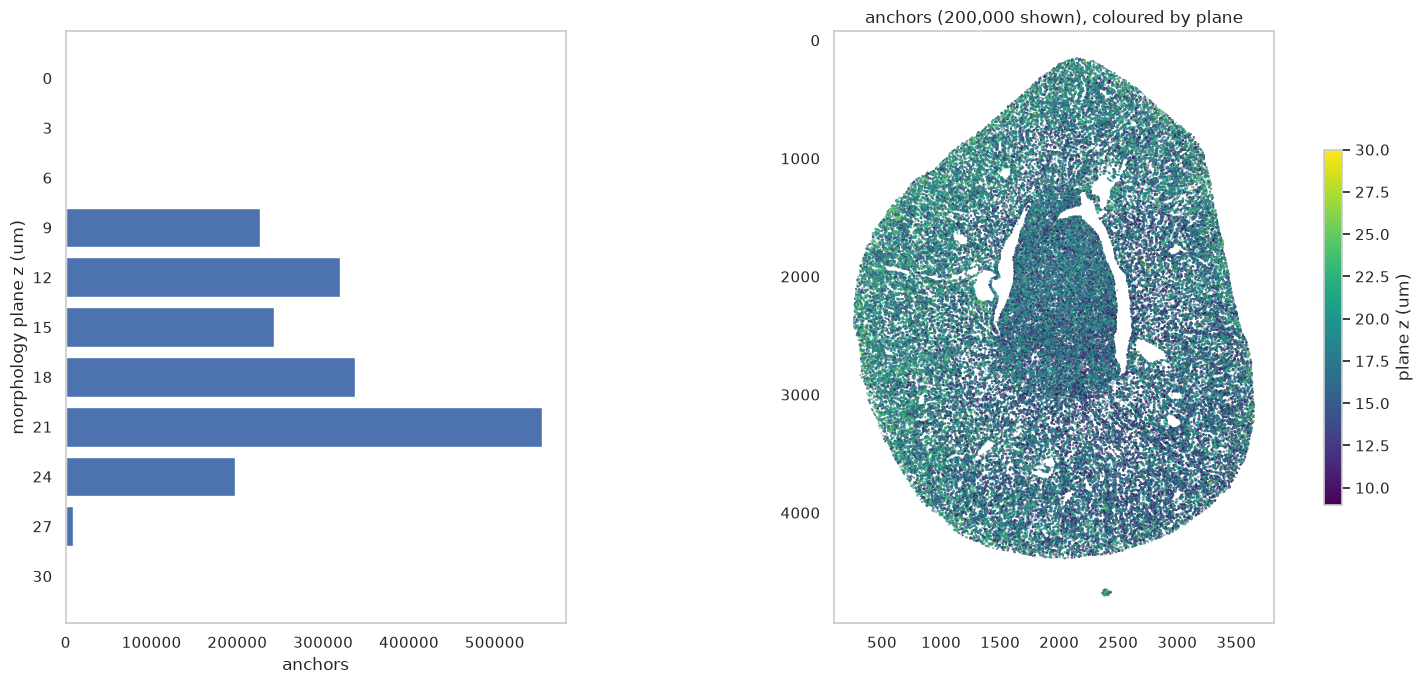

In [7]:
import pandas as pd

# obsm['spatial'] holds x, y (um); the anchor's lattice plane is obs['z_index'] (1 um steps from the store's z origin)
xy = adata.obsm["spatial"]
z_um = float(np.asarray(ds.zarr_group["coordinate_offset"][:])[2]) + adata.obs["z_index"].to_numpy()
plane_of = np.asarray(plane_z)[np.abs(z_um[:, None] - np.asarray(plane_z)[None, :]).argmin(1)]
per_plane = pd.Series(plane_of).value_counts().reindex(plane_z, fill_value=0)
print("anchors per morphology plane:")
print(per_plane.rename(index=lambda z: f"z = {z:4.1f} um").to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 2]})
axes[0].barh([f"{z:.0f}" for z in plane_z], per_plane.values, color="#4c72b0")
axes[0].invert_yaxis()
axes[0].set_xlabel("anchors")
axes[0].set_ylabel("morphology plane z (um)")
sub = np.random.default_rng(0).choice(len(xy), size=min(200_000, len(xy)), replace=False)
sc_ = axes[1].scatter(xy[sub, 0], xy[sub, 1], c=plane_of[sub], s=0.05, cmap="viridis", rasterized=True)
axes[1].set_aspect("equal")
axes[1].invert_yaxis()
axes[1].set_title("anchors (200,000 shown), coloured by plane")
plt.colorbar(sc_, ax=axes[1], shrink=0.6, label="plane z (um)")
plt.tight_layout()
plt.show()

## 4. Clustering

The anchors are clustered like single cells. `rapids_singlecell` runs PCA, the kNN graph and Leiden on the GPU.

In [8]:
import rapids_singlecell as rsc

rsc.pp.pca(adata, n_comps=50)
rsc.pp.neighbors(adata, n_neighbors=15)
rsc.tl.leiden(adata, resolution=1)
print(adata.obs["leiden"].nunique(), "clusters")
adata.write_h5ad(CLS)

39 clusters


## 5. Agentic annotation (outside the notebook)

Clusters are named by CeLLMan's **annotate-mode** skill, which runs in Claude Code or Codex rather than in this
kernel (see the README for installing the skill and the `annotate-expert` agent). Start it with a prompt like this,
filling in the absolute paths:

```
/annotate-mode Annotate the h5ad file below using the annotate-expert agent.

- input          : <SSAF-T>/notebooks/outputs/xenium_kidney/mouse_kidney_cls.h5ad
- tissue         : mouse, kidney, normal
- cluster column : leiden
- virtual env    : <path to the Python environment with ssaft installed>
- out            : <SSAF-T>/notebooks/outputs/xenium_kidney/annotation_out
```

It writes `mouse_kidney_cls_annotated.h5ad` with `obs['cellman_annotation']`, the rationale for every cluster, and
`celltype_markers.yaml`: the KG markers behind each label, which the mapping uses below.

In [2]:
import scanpy as sc

ANNO    = ANNOTATION / "mouse_kidney_cls_annotated.h5ad"
MARKERS = ANNOTATION / "celltype_markers.yaml"

anno = sc.read_h5ad(ANNO)
print(anno.obs["cellman_annotation"].value_counts().to_string())

cellman_annotation
proximal tubule cell S2                      363803
proximal tubule cell S3                      203983
thick ascending limb cell                    190140
proximal tubule cell S1                      163963
cortical thick ascending limb cell           140555
connecting tubule cell                        80313
proximal tubule cell                          68688
macrophage                                    66923
distal convoluted tubule cell                 66828
collecting duct principal cell                58892
descending thin limb cell                     58502
glomerular endothelial cell                   57339
distal convoluted tubule type 2 cell          47424
vascular smooth muscle cell                   44155
fibroblast                                    37933
type A intercalated cell                      31062
podocyte                                      30217
inner medullary descending thin limb cell     30117
mesenchymal cell                             

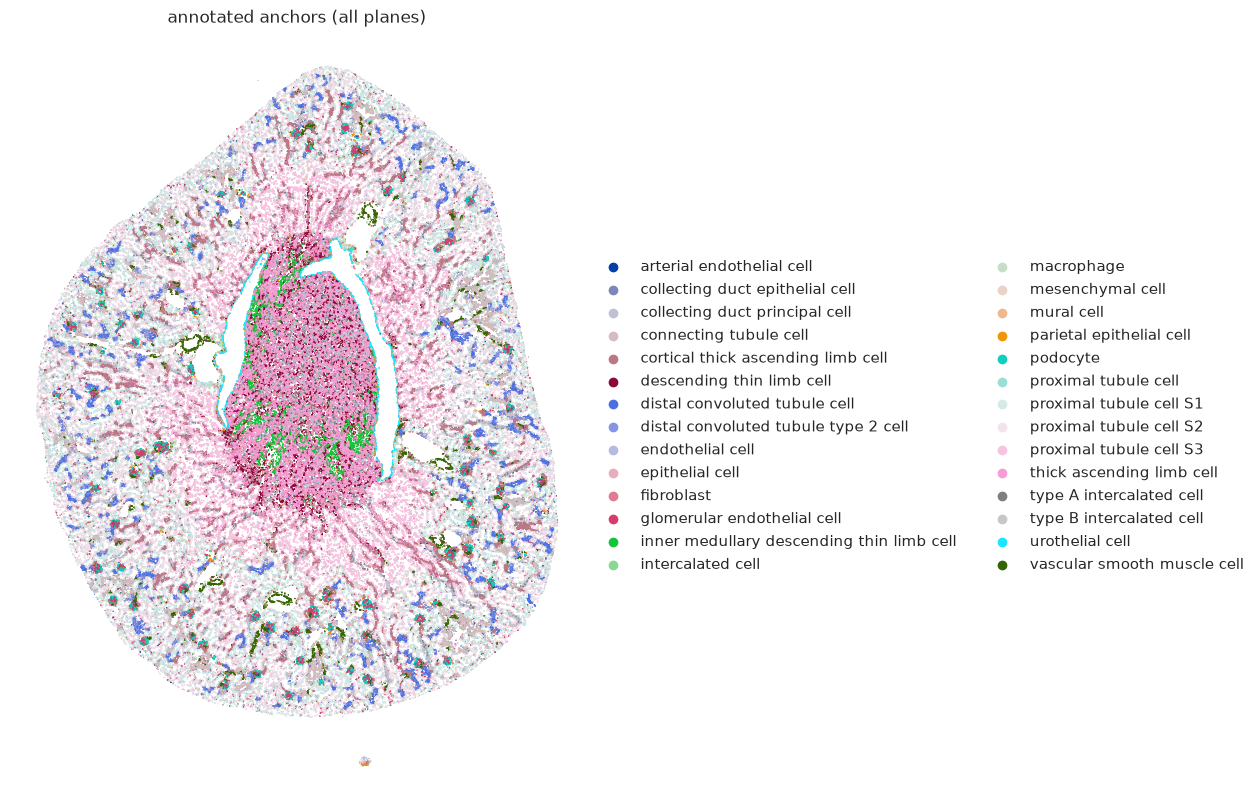

In [3]:
fig, ax = plt.subplots(figsize=(10, 10))
sc.pl.embedding(anno, basis="spatial", color="cellman_annotation", size=1, ax=ax, show=False, frameon=False,
                title="annotated anchors (all planes)")
ax.set_aspect("equal")
ax.invert_yaxis()
plt.show()

## 6. Cell-type mapping in 3D

The store records `n_dims = 3` from the downsampling, so `map_celltypes` computes the vector field on a 3D lattice
(`sampling_distance` µm in x, y and z) and assigns every voxel a cell type. `method='lda'` scores voxels against a
dictionary built from the annotated anchors. `marker_genes_path` gives each cell type its own KG markers, which
`filter_celltypemaps(hsm_f=...)` can use. The transcripts are read from `sdata`.

The annotation ran outside this kernel, so the store is re-opened first; the mapping builds its lattice from the
store and the whole section's transcripts.

In [4]:
ds = ssaft.Dataset(str(STORE))
analysis = ssaft.Analysis(ds, ncores=NCORES, verbose=True)

sdata = analysis.map_celltypes(sdata, method="lda", kernel="gaussian", bandwidth=2.5, sampling_distance=1.0,
                               h5ad=str(ANNO), marker_genes_path=str(MARKERS), gpu_device=DEVICE)
print("celltype_maps (x, y, z):", ds.zarr_group["celltype_maps"].shape)

zarr keys: ['celltype_maps', 'celltype_marker_score', 'celltype_names', 'centroids', 'cluster_labels', 'coordinate_bounds', 'coordinate_offset', 'downsampled_vectors', 'downsampled_vf_norm', 'filtered_celltype_maps', 'genes', 'max_probabilities', 'normalized_vectors', 'original_coordinate_bounds', 'vf_norm']
Loaded existing local maxima.
Loaded a precomputed normalized vector.


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at celltype_index.csv is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


Loaded existing gene list.
Loaded existing cluster labels.
Loaded existing cell type maps.
Loaded existing filtered cell type maps.
[map_celltypes] building centroids from mouse_kidney_cls_annotated.h5ad: 28 celltypes, 1887259 vectors
    id=  0  proximal tubule cell              [celltype]  (68688 vectors)
    id=  1  proximal tubule cell S2           [celltype]  (363803 vectors)
    id=  2  proximal tubule cell S3           [celltype]  (203983 vectors)
    id=  3  proximal tubule cell S1           [celltype]  (163963 vectors)
    id=  4  arterial endothelial cell         [celltype]  (5253 vectors)
    id=  5  endothelial cell                  [celltype]  (22215 vectors)
    id=  6  glomerular endothelial cell       [celltype]  (57339 vectors)
    id=  7  fibroblast                        [celltype]  (37933 vectors)
    id=  8  mesenchymal cell                  [celltype]  (26619 vectors)
    id=  9  mural cell                        [celltype]  (9272 vectors)
    id= 10  macrophage  

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=41, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


[map_celltypes] wrote cluster_labels (1887259,) + centroids (28, 541) + celltype_names (28) + colors (normalized_vectors untouched)
[map_celltypes] wrote outputs/xenium_kidney/ssaft_store/celltype_index.csv
map_celltypes: GPU path (cuda)
[lda] factors (28, 541) from 1,887,259 annotated vectors, 28 celltypes (28 real); core-weighted r=8 µm (median w=0.67, 0 classes softened), 2,132 owned gene slots at own_frac=0.5
map_celltypes: anchors span z, so the prior is 3D: a nearest-k_max lookup, on the GPU when the anchors sit on the voxel lattice and a CUDA device is used, else the KD-tree (the gridded prior is a 2D convolution)
map_celltypes: LDA scored on cuda


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=23, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
KDE: 100%|██████████| 603M/603M [21:45<00:00, 462kvox/s, chunk 99/99] 


[map_celltypes] tables['ssaft_downsampled_vectors'] (1887259, 541) 28 celltypes
celltype_maps (x, y, z): (4242, 5075, 28)


## 7. Filtering

`filter_celltypemaps` removes voxels where there is no cell. With the defaults, each cell type is cut at `norm_f = 0.3`
of its own density peak, after each plane's density is normalised by that plane's median (`norm_depth=True`), because
density falls off away from the middle of the section. The filtered map is written back to the store and added to
`sdata` as `labels['ssaft_celltype_map']`, every layer as `(z, y, x)`, and `images['ssaft_celltype_map_rgb']`, an RGB
rendering of the middle layer (`int(n_layers / 2)`).

In [5]:
sdata = analysis.filter_celltypemaps(sdata)

filter_celltypemaps: norm_f=0.3 -> 11,831,779 of 142,057,587 voxels below their celltype's density cut (28 celltypes, density normalised over 27 planes)
[write_celltype_map] labels['ssaft_celltype_map'] (28, 5075, 4242) (z, y, x) + images['ssaft_celltype_map_rgb'] layer z=14 (28 celltypes) @ 1.0µm/px, origin=(0.7,1.2)


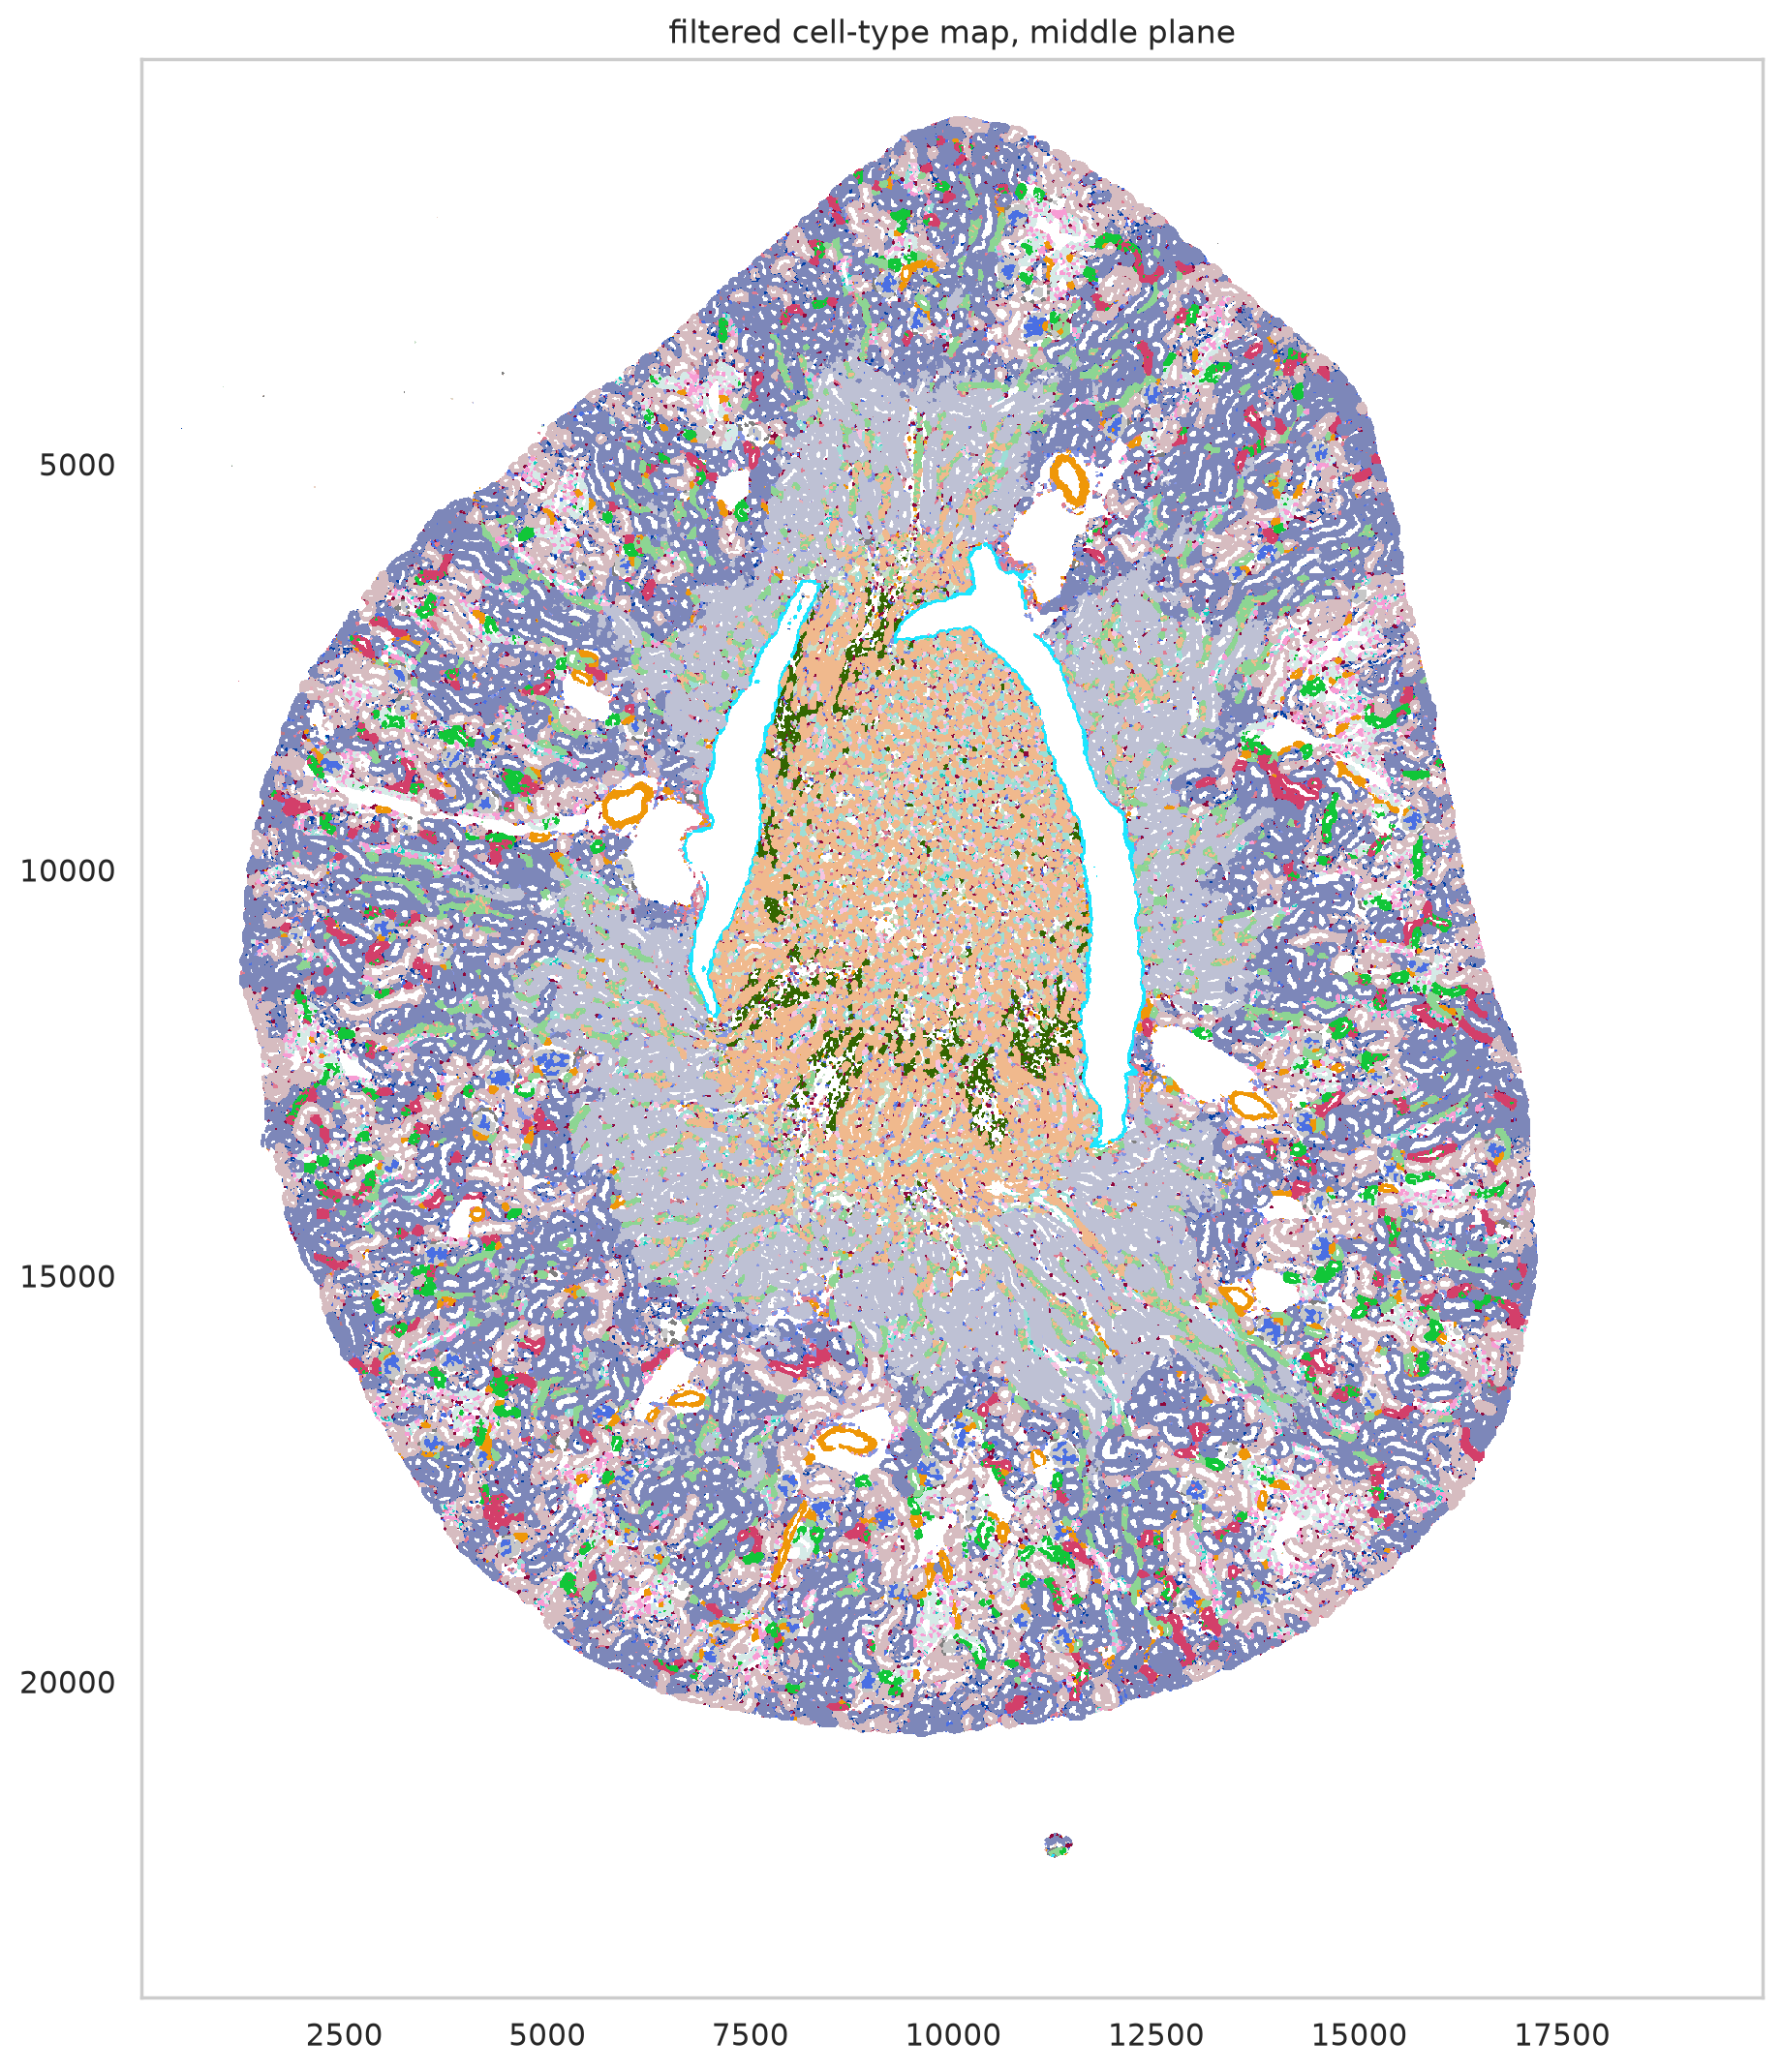

In [6]:
import spatialdata_plot
from matplotlib.colors import Normalize

fig, ax = plt.subplots(figsize=(11, 13), dpi=200)
sdata.pl.render_images("ssaft_celltype_map_rgb", norm=Normalize(vmin=0, vmax=255)).pl.show(ax=ax)
ax.get_images()[0].set_interpolation("nearest")
ax.set_title("filtered cell-type map, middle plane")
plt.show()

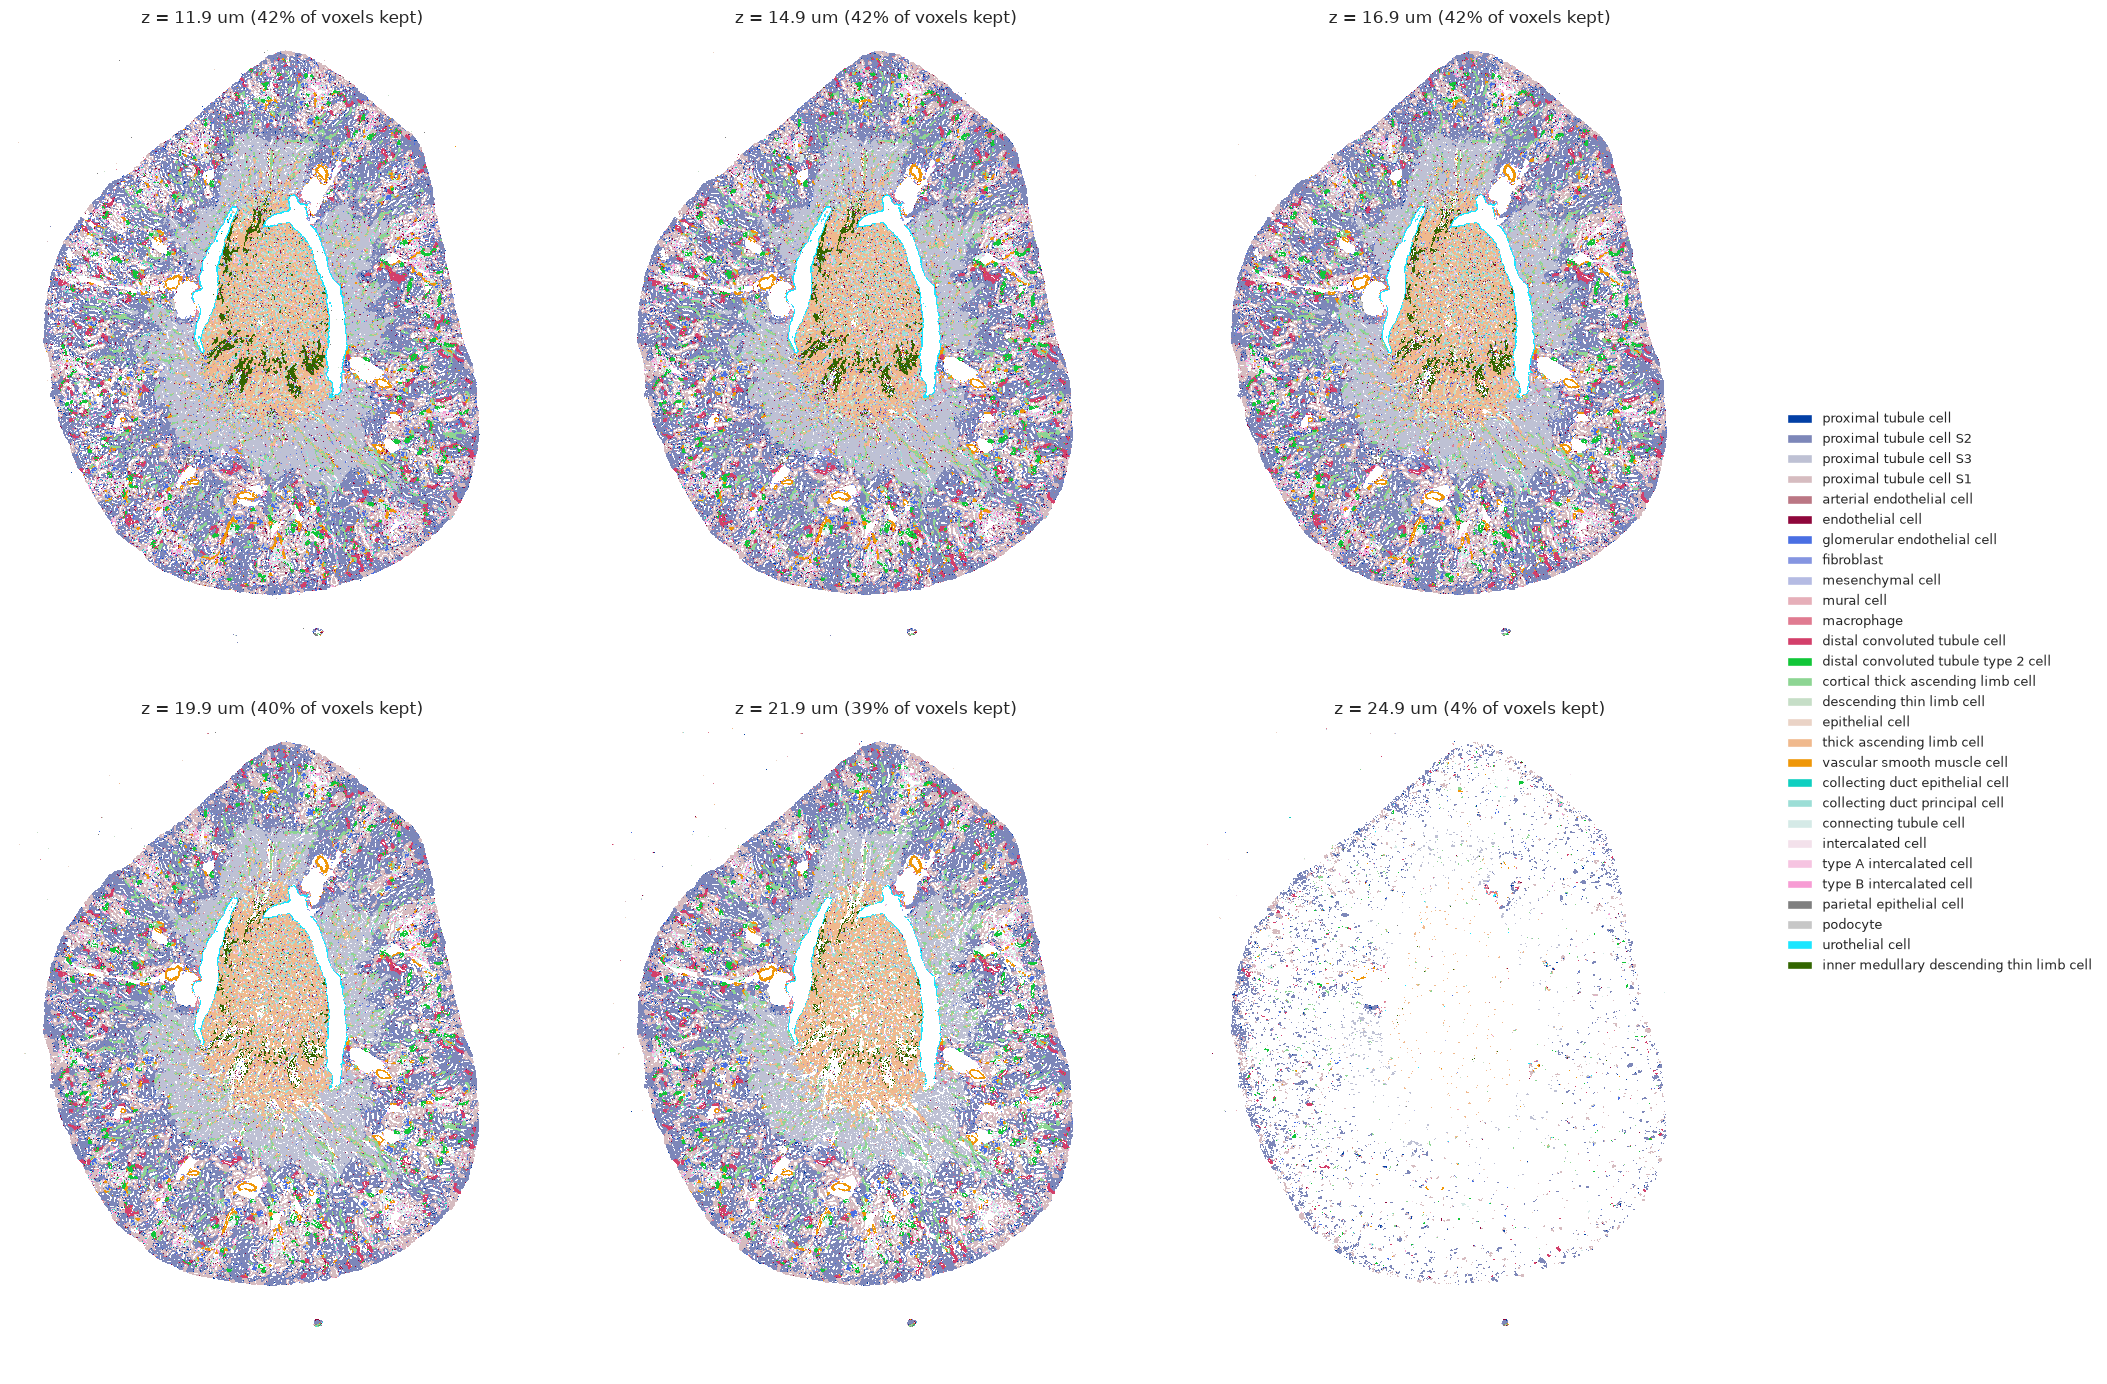

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

names, colors = ds.celltype_names_colors()
fmap = ds.zarr_group["filtered_celltype_maps"]              # (x, y, z), -1 = background
z0 = float(np.asarray(ds.zarr_group["coordinate_offset"][:])[2])
cmap = ListedColormap(["white"] + list(colors))            # value + 1 -> colour

planes = np.linspace(fmap.shape[2] * 0.3, fmap.shape[2] * 0.75, 6).round().astype(int)
fig, axes = plt.subplots(2, 3, figsize=(18, 14))
for k, ax in zip(planes, axes.flat):
    lab = np.asarray(fmap[:, :, k]).T + 1
    ax.imshow(lab, cmap=cmap, vmin=0, vmax=len(colors), interpolation="nearest")
    kept = (lab > 0).mean()
    ax.set_title(f"z = {z0 + k:.1f} um ({kept:.0%} of voxels kept)")
    ax.axis("off")
present = np.unique(np.asarray(fmap[:, :, planes[len(planes) // 2]]))
fig.legend(handles=[Patch(facecolor=colors[i], label=names[i]) for i in present if i >= 0],
           loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 8. Segmentation

`segment_cells` turns the map into single cells: one watershed per cell type, seeded by nuclei and confined to that
cell type's region. Different cell types are separated where the map changes type, and cells of the same type are
separated halfway between their nuclei.

The store is 3D (`n_dims = 3`), so the watershed runs in 3D, over every layer of the filtered map:

- **markers**: a marker only says where the water is poured. Each nucleus centroid is one seed on the map's middle
  layer, and its cell type is the map's label there;
- **flood**: per cell type, in 3D, within that type's voxels.

It writes `labels['ssaft_cell_labels_3d']` (the 3D cells), `shapes['ssaft_cell_boundaries_3d']` (every cell's outline
on every layer), `shapes['ssaft_cell_boundaries_2d']` (the map's middle layer, the layer of
`images['ssaft_celltype_map_rgb']`) and `tables['ssaft_cells']` (cell × gene
counts by 3D voxel, with each cell's volume and number of layers). All of them sit in the same `global` pixel frame as
the morphology images and the nucleus boundaries.

In [8]:
sdata = analysis.segment_cells(sdata, nuclei="nucleus_boundaries")
cells = sdata.tables["ssaft_cells"]
print(cells)
print(cells.uns["segment_cells"])
print(cells.obs[["volume_um3", "n_z", "max_plane_area_um2"]].describe().round(1).to_string())
print(cells.obs["cellman_annotation"].value_counts()[lambda s: s > 0].to_string())

segment_cells: markers read in intrinsic frame (100.0% inside the map; other frame 0.0%)
segment_cells: counting points['transcripts'] in 3D
[segment_cells] labels['ssaft_cell_labels_3d'] 83326 cells in 3D from 83558/84419 nuclei (861 on background on the seed layer ignored, 0 outside map, 232 below 5.0µm² on every layer) @ all 28 layers, seeds on layer 14, 1.0µm/voxel
[segment_cells] shapes['ssaft_cell_boundaries_3d'] 1249454 outlines on 28 layers; shapes['ssaft_cell_boundaries_2d'] 83326 on the middle layer z=14
[segment_cells] tables['ssaft_cells'] (83326, 541) (12,505,926 transcripts assigned, median volume 1257µm³)
AnnData object with n_obs × n_vars = 83326 × 541
    obs: 'cellman_annotation', 'celltype_id', 'label_id', 'cell_id', 'volume_um3', 'n_z', 'max_plane_area_um2', 'area_um2', 'region'
    uns: 'cellman_annotation_colors', 'cellman_celltype_names', 'segment_cells', 'spatialdata_attrs'
    obsm: 'spatial'
{'n_dims': 3, 'z_layers': [0, 27], 'seed_layer': 14, 'z_um': [3.89571

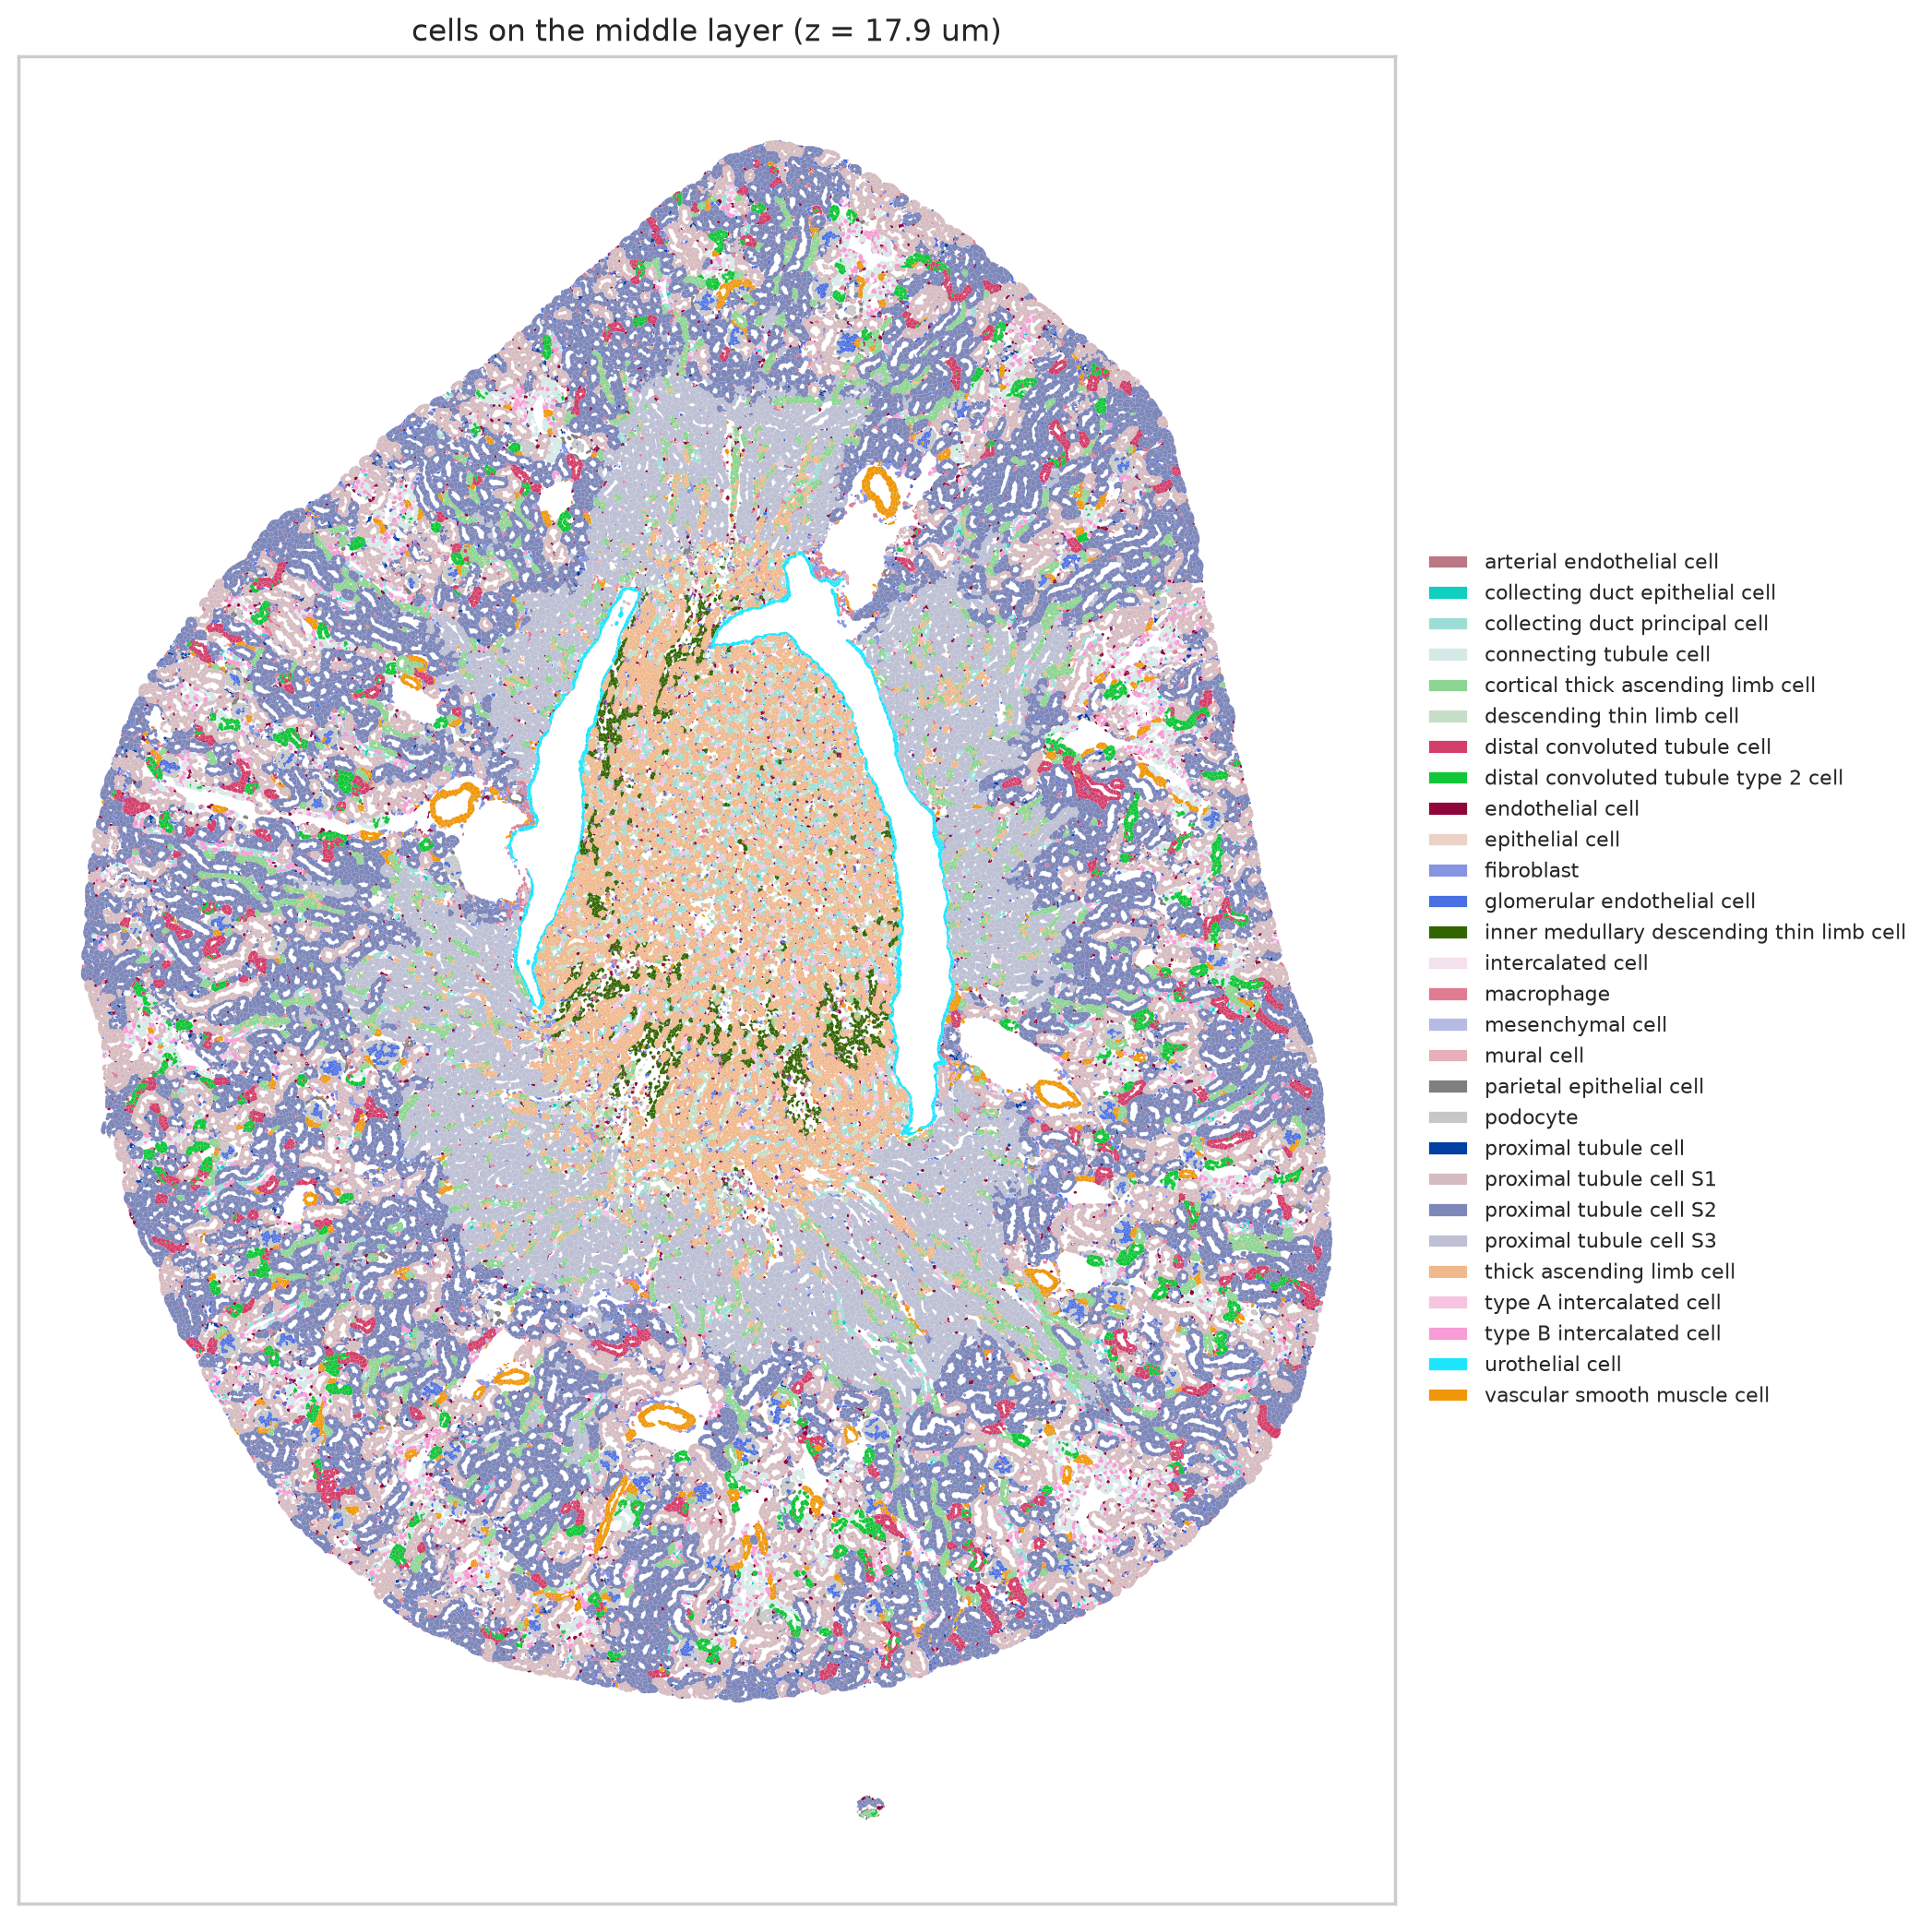

/tmp/ipykernel_2928777/3429566336.py:26: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  part.plot(ax=ax, color=[lut[c] for c in lab_p], edgecolor="white", linewidth=0.3)
/tmp/ipykernel_2928777/3429566336.py:26: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  part.plot(ax=ax, color=[lut[c] for c in lab_p], edgecolor="white", linewidth=0.3)


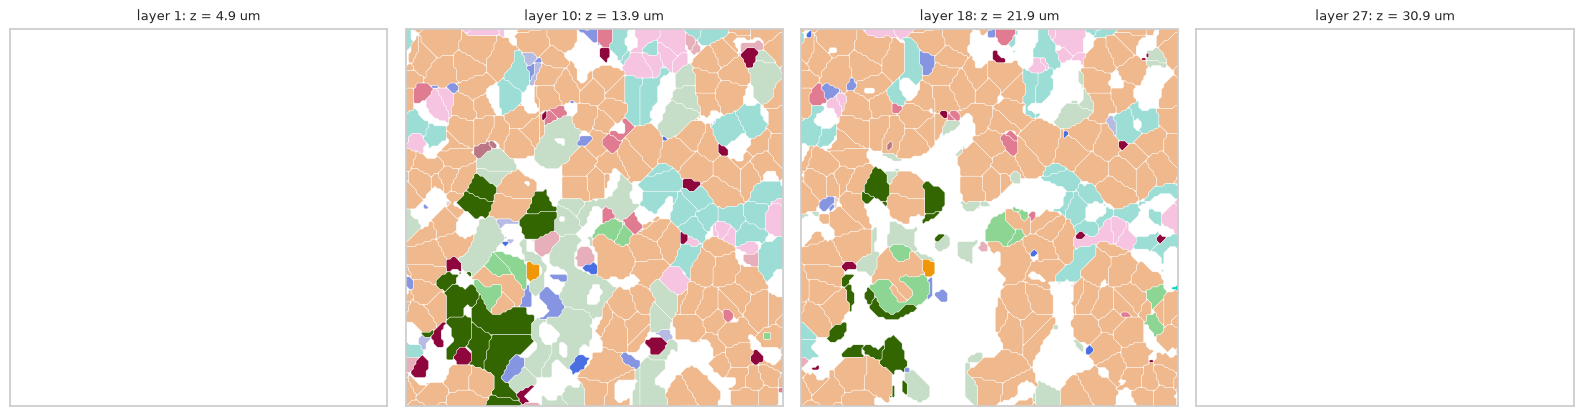

In [9]:
lut = dict(zip(names, colors))
g2 = sdata.shapes["ssaft_cell_boundaries_2d"]
lab = cells.obs.loc[g2.index, "cellman_annotation"].astype(str).to_numpy()

fig, ax = plt.subplots(figsize=(11, 13), dpi=200)
g2.plot(ax=ax, color=[lut[c] for c in lab], linewidth=0)
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"cells on the middle layer (z = {cells.uns['segment_cells']['middle_z_um']:.1f} um)")
ax.legend(handles=[Patch(facecolor=lut[c], label=c) for c in sorted(set(lab))],
          loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
plt.show()

# the same cells on four layers of a 150 um window
g3 = sdata.shapes["ssaft_cell_boundaries_3d"]
layers = sorted(g3["z_index"].unique())
show = [layers[i] for i in np.linspace(0, len(layers) - 1, 4).round().astype(int)]
cx, cy = float(g2.geometry.centroid.x.median()), float(g2.geometry.centroid.y.median())
win = g3.cx[cx - 75:cx + 75, cy - 75:cy + 75]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, zi in zip(axes, show):
    part = win[win["z_index"] == zi]
    lab_p = cells.obs.loc[part["cell_id"], "cellman_annotation"].astype(str).to_numpy()
    part.plot(ax=ax, color=[lut[c] for c in lab_p], edgecolor="white", linewidth=0.3)
    ax.set_xlim(cx - 75, cx + 75)
    ax.set_ylim(cy + 75, cy - 75)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"layer {zi}: z = {float(g3.loc[g3['z_index'] == zi, 'z_um'].iloc[0]):.1f} um", fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
sd.SpatialData(labels={"ssaft_cell_labels_3d": sdata.labels["ssaft_cell_labels_3d"]},
               shapes={k: sdata.shapes[k] for k in ("ssaft_cell_boundaries_2d", "ssaft_cell_boundaries_3d")},
               tables={"ssaft_cells": sdata.tables["ssaft_cells"]}).write(OUT / "ssaft_cells.zarr")
cells.write_h5ad(OUT / "ssaft_cells.h5ad")

/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the